In [1]:
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(1)

In [4]:
# load the flower photos

train_data = keras.utils.image_dataset_from_directory(
    "flowers_small/",
    validation_split=0.2, 
    subset="training", 
    seed=1,
    image_size=(160,160), 
    batch_size=32
)

val_data = keras.utils.image_dataset_from_directory(
    "flowers_small/", 
    validation_split=0.2,
    subset="validation",
    seed=1,
    image_size=(160,160),
    batch_size=32
)

class_names = train_data.class_names
print("Classes:", class_names)

Found 500 files belonging to 5 classes.
Using 400 files for training.
Found 500 files belonging to 5 classes.
Using 100 files for validation.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [21]:
# build the model (frozen model)

base = keras.applications.MobileNetV2(
    input_shape=(160,160,3),
    include_top=False,
    weights="imagenet"
)
base.trainable = False

model = keras.Sequential([
    layers.Input(shape=(160,160,3)),
    layers.Rescaling(1/127.5, offset=1),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [23]:
# train the new top first

first = model.fit(train_data, validation_data=val_data, epochs=3)

accuracy_before = model.evaluate(val_data, verbose=0)[1]
print("Acuracy with the base frozen:", round(accuracy_before,5))

Epoch 1/3
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 590ms/step - accuracy: 0.7675 - loss: 0.6384 - val_accuracy: 0.7800 - val_loss: 0.7614
Epoch 2/3
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 485ms/step - accuracy: 0.8225 - loss: 0.5411 - val_accuracy: 0.8000 - val_loss: 0.7253
Epoch 3/3
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 493ms/step - accuracy: 0.8300 - loss: 0.4958 - val_accuracy: 0.8000 - val_loss: 0.7019
Acuracy with the base frozen: 0.8


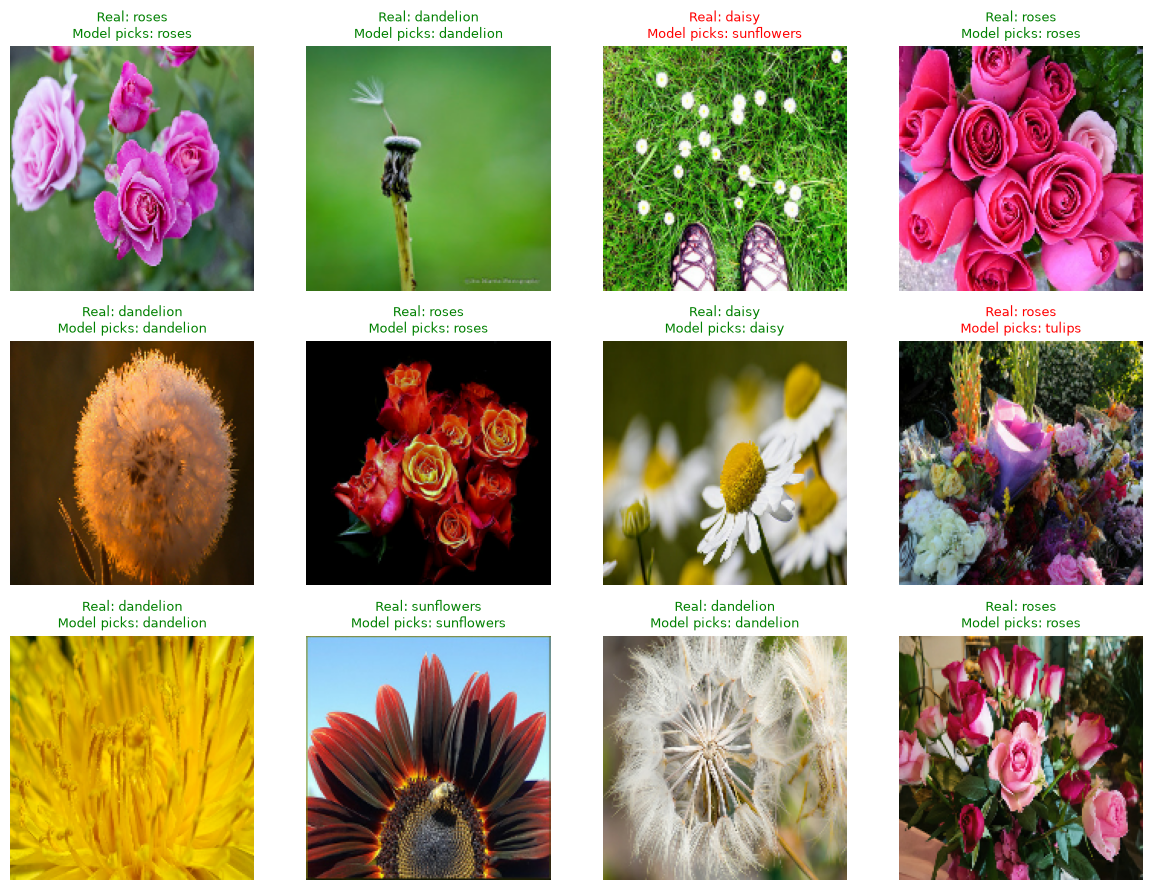

In [24]:
# try some photos

for images, labels in val_data.take(1):
    sample_images = images[:12]
    sample_labels = labels[:12].numpy()
 
probabilities = model.predict(sample_images, verbose=0)
before = probabilities.argmax(axis=1)
 
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for i, ax in enumerate(axes.flat):
    ax.imshow(sample_images[i].numpy().astype("uint8"))
    ax.set_title("Real: " + class_names[sample_labels[i]]
                 + "\nModel picks: " + class_names[before[i]],
                 fontsize=9, color="green" if before[i] == sample_labels[i] else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()
 

In [26]:
# build the model (after unfreeze model/fine-tuing)

base.trainable = True
 
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
 
second = model.fit(train_data, validation_data=val_data, epochs=5)
 
accuracy_after = model.evaluate(val_data, verbose=0)[1]
print("Accuracy after fine-tuning:", round(accuracy_after, 3))

Epoch 1/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 63s 2s/step - accuracy: 0.8275 - loss: 0.5191 - val_accuracy: 0.8000 - val_loss: 0.6414
Epoch 2/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 30s 2s/step - accuracy: 0.8500 - loss: 0.4737 - val_accuracy: 0.8000 - val_loss: 0.6308
Epoch 3/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.8675 - loss: 0.4088 - val_accuracy: 0.7900 - val_loss: 0.6197
Epoch 4/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 34s 3s/step - accuracy: 0.9075 - loss: 0.3464 - val_accuracy: 0.8000 - val_loss: 0.6124
Epoch 5/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step - accuracy: 0.9375 - loss: 0.2816 - val_accuracy: 0.8000 - val_loss: 0.6043
Accuracy after fine-tuning: 0.8


Correct before fine-tuning: 10 out of 12
Correct after fine-tuning:  10 out of 12


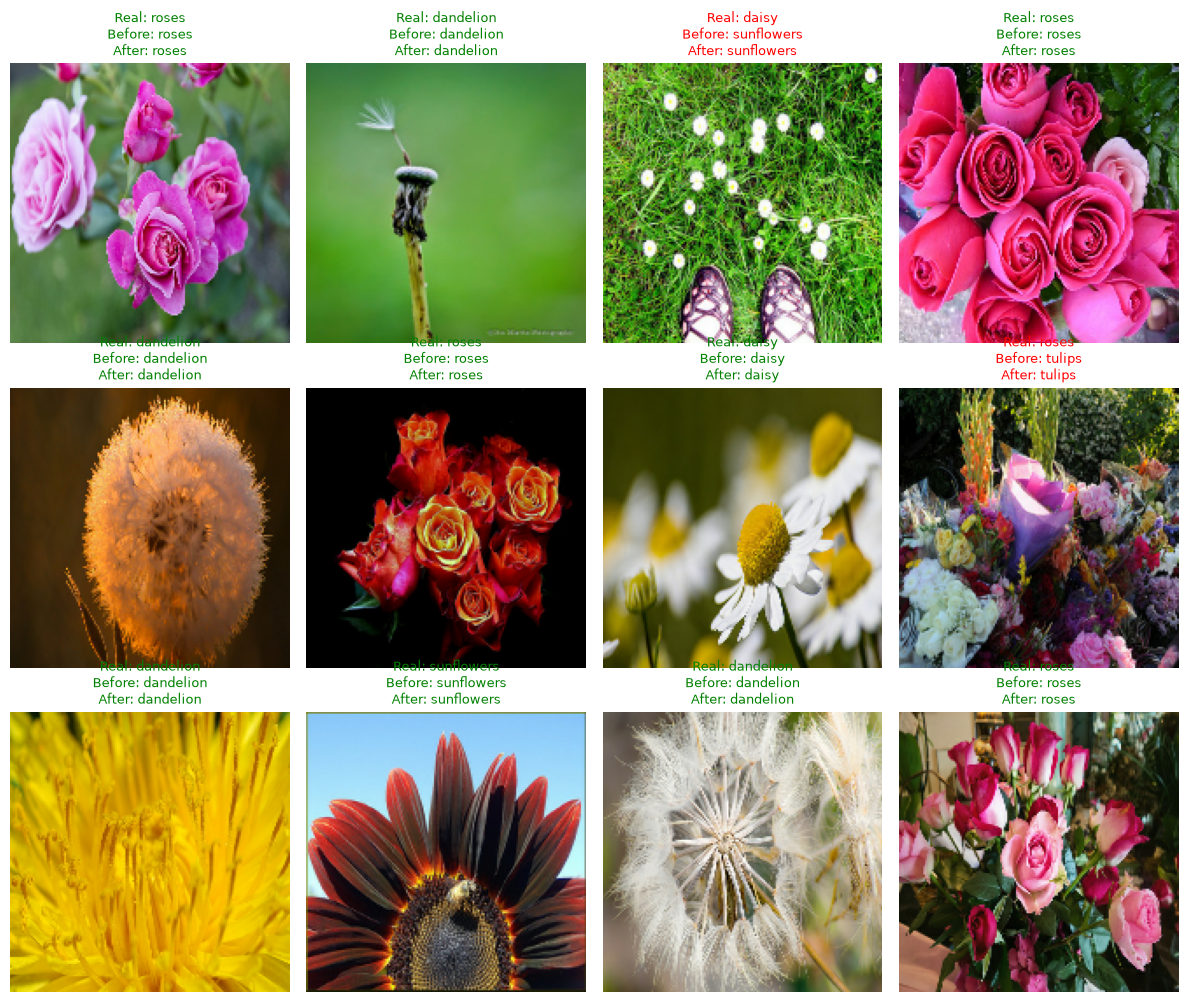

In [27]:
# ask the same photos again

after = model.predict(sample_images, verbose=0).argmax(axis=1)
print("Correct before fine-tuning:", int((before == sample_labels).sum()), "out of 12")
print("Correct after fine-tuning: ", int((after == sample_labels).sum()), "out of 12")
 
fig, axes = plt.subplots(3, 4, figsize=(12, 10))
for i, ax in enumerate(axes.flat):
    ax.imshow(sample_images[i].numpy().astype("uint8"))
    ax.set_title("Real: " + class_names[sample_labels[i]]
                 + "\nBefore: " + class_names[before[i]]
                 + "\nAfter: " + class_names[after[i]],
                 fontsize=9, color="green" if after[i] == sample_labels[i] else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()